# Лабораторная работа № 5
## Визуализация данных. Matplotlib, Seaborn, Plotly

**Среда выполнения:** Google Colab + GitLab

**Прикладная задача:** «Визуальная аналитика продаж интернет-магазина» — построить модуль, который загружает и проверяет данные о заказах, агрегирует их средствами pandas, строит статические и интерактивные графики и собирает их в единый HTML-отчёт.

**Автор:** <ФИО>

**Группа:** <номер группы>

**Дата:** <дата>

---
## Часть I. Теория

### 1. Зачем нужна визуализация

**Визуализация** — это представление данных в графической форме. График позволяет за несколько секунд увидеть то, что в таблице незаметно: тренды, сезонность, выбросы, связи между величинами.

Классический пример — квартет Энскомба: четыре набора точек с одинаковыми средними, дисперсиями и коэффициентом корреляции, которые на графике выглядят совершенно по-разному. Поэтому анализ данных начинают с графиков, а не с итоговых чисел.

В Python для визуализации чаще всего используют следующие библиотеки:

| Библиотека | Особенность | Когда применять |
|---|---|---|
| Matplotlib | Базовая библиотека, полный контроль над каждым элементом графика | Статические графики для отчётов и статей |
| Seaborn | Надстройка над Matplotlib, работает напрямую с DataFrame | Статистический анализ: распределения, сравнение групп |
| Plotly | Интерактивные графики в браузере: масштаб, подсказки, фильтры | Дашборды, исследование данных, HTML-отчёты |
| pandas (`.plot()`) | Обёртка над Matplotlib прямо у DataFrame | Быстрый взгляд на данные в ноутбуке |

### 1.1. Подготовка данных: минимум pandas

Прежде чем строить график, данные почти всегда нужно сгруппировать и агрегировать. Для этого используется библиотека **pandas**. Её основные объекты: **Series** — одномерный столбец с индексом и **DataFrame** — таблица из нескольких столбцов.

```python
import pandas as pd

df = pd.read_csv("lab5_data/orders.csv", parse_dates=["order_datetime"])
df["total"] = df["unit_price"] * df["quantity"]

df.head()      # первые 5 строк
df.info()      # типы столбцов и пропуски
df.describe()  # основные статистики по числовым столбцам
```

Операции, которые понадобятся в этой работе:

| Операция | Пример | Результат |
|---|---|---|
| Фильтрация | `df[df["status"] == "completed"]` | Строки, удовлетворяющие условию |
| Группировка | `df.groupby("category")["total"].sum()` | Сумма по каждой категории |
| Несколько агрегатов | `df.groupby("city").agg(revenue=("total", "sum"), orders=("order_id", "count"))` | Таблица с двумя столбцами |
| Сводная таблица | `df.pivot_table(index="month", columns="category", values="total", aggfunc="sum")` | Таблица «месяц × категория» |
| Группировка по времени | `df.groupby(pd.Grouper(key="order_datetime", freq="ME"))["total"].sum()` | Сумма по месяцам |
| Компоненты даты | `df["order_datetime"].dt.month`, `.dt.hour`, `.dt.day_of_week` | Месяц, час, день недели |

Обратите внимание: в pandas 2.2 и новее месячная частота обозначается `"ME"` (month end). Старое обозначение `"M"` выдаёт предупреждение, а в следующих версиях будет удалено.

### 2. Matplotlib

### 2.1. Анатомия графика

*   **Figure** — «холст», контейнер верхнего уровня. Именно его сохраняют в файл.
*   **Axes** — область построения с осями координат. На одной Figure может быть несколько Axes.
*   **Axis** — отдельная ось (x или y) с делениями и подписями.
*   **Artist** — любой видимый элемент: линия, текст, легенда, прямоугольник.

У Matplotlib два интерфейса:

*   **pyplot** — функции `plt.plot()`, `plt.title()` работают с «текущими» осями, которые библиотека хранит у себя. Удобен для быстрых набросков.
*   **Объектно-ориентированный** — оси создаются явно (`fig, ax = plt.subplots()`), и вызываются методы конкретного объекта `ax`. Внутри функций используют только его: функция получает или создаёт свои оси и не зависит от глобального состояния (вспомните `global` из ЛР2).

```python
import matplotlib.pyplot as plt

months = ["Янв", "Фев", "Мар", "Апр", "Май", "Июн"]
revenue = [23.3, 17.2, 26.1, 22.3, 28.8, 23.5]  # млн руб.

# pyplot-интерфейс
plt.plot(months, revenue)
plt.title("Выручка")
plt.show()

# объектный интерфейс
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(months, revenue, marker="o")
ax.set_title("Выручка за первое полугодие")
ax.set_xlabel("Месяц")
ax.set_ylabel("Выручка, млн руб.")
ax.grid(alpha=0.3)
plt.show()
```

### 2.2. Основные типы графиков

| Тип | Метод Axes | Что показывает |
|---|---|---|
| Линейный | `ax.plot()` | Изменение величины во времени |
| Столбчатый | `ax.bar()`, `ax.barh()` | Сравнение категорий |
| Гистограмма | `ax.hist()` | Распределение одной числовой величины |
| Диаграмма рассеяния | `ax.scatter()` | Связь двух числовых величин |
| «Ящик с усами» | `ax.boxplot()` | Медиана, квартили и выбросы |
| Круговая | `ax.pie()` | Доли целого (только при 2–4 категориях) |

### 2.3. Несколько графиков на одной фигуре

`plt.subplots(nrows, ncols)` возвращает Figure и массив Axes. Параметры `sharex`/`sharey` делают оси общими, а `layout="constrained"` автоматически подбирает отступы, чтобы подписи не налезали друг на друга.

```python
fig, axes = plt.subplots(1, 2, figsize=(12, 4), layout="constrained")

axes[0].bar(["web", "mobile", "marketplace"], [1350, 1050, 600])
axes[0].set_title("Заказы по каналам")

axes[1].hist(df["total"], bins=30)
axes[1].set_title("Распределение суммы заказа")

fig.suptitle("Обзор продаж")
plt.show()
```

### 2.4. Оформление и сохранение

*   Подписи: `ax.set_title()`, `ax.set_xlabel()`, `ax.set_ylabel()`. Легенда — `ax.legend()`, текст берётся из параметра `label=` при построении.
*   Форматирование делений: `matplotlib.ticker.FuncFormatter` позволяет, например, выводить 1 500 000 как «1.5 млн».
*   Подписи значений над столбцами: `ax.bar_label(bars)`.
*   Аннотации со стрелкой: `ax.annotate(text, xy=..., xytext=..., arrowprops=...)`.
*   Сохранение: `fig.savefig("chart.png", dpi=150, bbox_inches="tight")`. Формат определяется расширением: PNG — растровый, SVG и PDF — векторные.
*   Закрытие: `plt.close(fig)`. Если строить графики в цикле и не закрывать их, Matplotlib держит все фигуры в памяти, а после 20 открытых фигур выдаёт предупреждение.

```python
from matplotlib.ticker import FuncFormatter

def to_millions(value: float, _pos: int) -> str:
    return f"{value / 1_000_000:.1f} млн"

fig, ax = plt.subplots()
bars = ax.bar(["Laptop", "Phone", "Tablet"], [48_500_000, 31_200_000, 12_700_000])
ax.yaxis.set_major_formatter(FuncFormatter(to_millions))
ax.bar_label(bars, labels=[to_millions(b.get_height(), 0) for b in bars])
fig.savefig("categories.png", dpi=150, bbox_inches="tight")
plt.close(fig)
```

### 3. Seaborn

Seaborn построен поверх Matplotlib и работает с DataFrame в **«длинном» формате** (tidy data): каждая строка — одно наблюдение, каждый столбец — одна переменная. Вместо циклов по группам достаточно указать имена столбцов в параметрах `x=`, `y=` и `hue=` (цвет по группе).

Функции Seaborn уровня осей принимают параметр `ax=` и возвращают Axes, поэтому их можно свободно комбинировать с `plt.subplots()`.

| Функция | Назначение |
|---|---|
| `sns.histplot()` | Гистограмма, в том числе с разбивкой по `hue` |
| `sns.boxplot()`, `sns.violinplot()` | Сравнение распределений между группами |
| `sns.barplot()` | Оценка по группам (по умолчанию — среднее) с доверительным интервалом |
| `sns.lineplot()` | Линии с агрегацией повторяющихся значений x |
| `sns.scatterplot()` | Диаграмма рассеяния с `hue` и `size` |
| `sns.heatmap()` | Матрица значений в цвете, например сводная таблица |

```python
import seaborn as sns

sns.set_theme(style="whitegrid")

fig, ax = plt.subplots(figsize=(8, 4))
sns.boxplot(data=df, x="category", y="total", ax=ax)
ax.set_yscale("log")  # суммы заказов отличаются на порядки
ax.set_title("Сумма заказа по категориям")
plt.show()
```

**Важно:** `sns.barplot` по умолчанию показывает **среднее**, а не сумму. Чтобы получить сумму, передайте `estimator="sum"`. Это частая ошибка в отчётах: столбец «выручка по каналу» на самом деле оказывается средним чеком.

**Ещё одна ловушка:** `sns.set_theme()` меняет глобальные настройки Matplotlib, в том числе цвет контуров по умолчанию. Если после него стрелка в `ax.annotate` пропала, задайте цвет явно: `arrowprops={"arrowstyle": "->", "color": "black"}`.

### 4. Plotly

Plotly строит интерактивные графики: их можно масштабировать, наводить курсор для подсказок, скрывать серии щелчком по легенде. Высокоуровневый модуль `plotly.express` по синтаксису похож на Seaborn: принимает DataFrame и имена столбцов.

```python
import plotly.express as px

monthly = (
    df.groupby(pd.Grouper(key="order_datetime", freq="ME"))["total"]
    .sum()
    .reset_index()
)
fig = px.line(monthly, x="order_datetime", y="total", markers=True,
              title="Выручка по месяцам",
              labels={"order_datetime": "Месяц", "total": "Выручка, руб."})
fig.show()
fig.write_html("revenue.html")
```

В Google Colab `fig.show()` отображает график прямо в ячейке. Метод `write_html()` сохраняет самостоятельный HTML-файл, который открывается в любом браузере без Python. Для сохранения в PNG нужен дополнительный пакет `kaleido`.

### 5. Выбор типа графика

Неправильно выбранный график искажает выводы не хуже ошибки в расчётах.

| Задача | Подходящий график | Чего избегать |
|---|---|---|
| Динамика во времени | Линейный | Столбцы при большом числе точек |
| Сравнение категорий | Столбчатый, отсортированный по значению | Круговая диаграмма с 5 и более секторами |
| Распределение | Гистограмма, «ящик с усами» | Одно среднее без разброса |
| Связь двух величин | Диаграмма рассеяния | Линия, соединяющая несвязанные точки |
| Структура целого | Составные столбцы; круговая при 2–4 долях | 3D-эффекты |
| Две категориальные оси | Тепловая карта | Десяток отдельных графиков |

Общие правила:

*   у столбчатой диаграммы ось Y начинается с нуля, иначе разница визуально преувеличивается;
*   у каждого графика есть заголовок и подписанные оси с единицами измерения;
*   цвет несёт смысл: одна категория — один цвет на всех графиках отчёта;
*   несколько простых графиков лучше, чем один перегруженный.

---
## Примеры

В качестве прикладной задачи продолжим аналитику интернет-магазина из ЛР2. Теперь у каждого заказа есть дата и время, город доставки и канал продаж, а результат нужно представить не текстовым отчётом, а набором графиков.

**Инициализация данных** (одинакова для примеров и заданий 11–20). Запустите эту ячейку один раз — данные будут использоваться во всех примерах и заданиях.

In [1]:
import os
import csv
import random
from datetime import datetime, timedelta

random.seed(42)

os.makedirs("lab5_data", exist_ok=True)
os.makedirs("lab5_output", exist_ok=True)

# Города доставки и их координаты (широта, долгота) — понадобятся для карты
CITIES = {
    "Москва": (55.76, 37.62),
    "Санкт-Петербург": (59.94, 30.31),
    "Казань": (55.79, 49.12),
    "Нижний Новгород": (56.33, 44.00),
    "Екатеринбург": (56.84, 60.61),
    "Новосибирск": (55.03, 82.92),
    "Краснодар": (45.04, 38.98),
    "Владивосток": (43.12, 131.89),
}
CITY_WEIGHTS = [32, 17, 8, 7, 9, 8, 12, 7]

# Категория: (минимальная цена, максимальная цена, максимальное количество)
CATEGORIES = {
    "Laptop": (45000, 250000, 2),
    "Phone": (15000, 150000, 2),
    "Tablet": (20000, 120000, 2),
    "Accessories": (500, 15000, 5),
}
CATEGORY_WEIGHTS = [20, 35, 15, 30]
BRANDS = ["Apple", "Samsung", "Lenovo", "Asus", "Xiaomi"]
CHANNELS = ["web", "mobile", "marketplace"]
CHANNEL_WEIGHTS = [45, 35, 20]
STATUSES = ["completed", "shipped", "pending", "cancelled"]
STATUS_WEIGHTS = [72, 10, 6, 12]

# Сезонность: ноябрь — распродажи, декабрь — подарки к Новому году
SEASON = [0.8, 0.7, 0.9, 0.9, 1.0, 0.9, 0.8, 0.9, 1.1, 1.0, 1.6, 1.8]
# Активность покупателей по часам суток (0–23)
HOURS = [1, 1, 1, 1, 1, 1, 2, 4, 6, 8, 9, 10,
         11, 10, 9, 9, 10, 12, 14, 15, 14, 11, 6, 3]

start = datetime(2025, 1, 1)
records = []
for _ in range(3000):
    # Дату выбираем с учётом сезонности: летом заказов меньше, зимой больше
    while True:
        day = start + timedelta(days=random.randint(0, 364))
        if random.random() < SEASON[day.month - 1] / max(SEASON):
            break
    hour = random.choices(range(24), weights=HOURS)[0]
    moment = day.replace(hour=hour, minute=random.randint(0, 59))

    category = random.choices(list(CATEGORIES), weights=CATEGORY_WEIGHTS)[0]
    low, high, max_qty = CATEGORIES[category]
    price = round(random.randint(low, high), -2) - 10  # цены вида 64 990
    records.append([
        moment.strftime("%Y-%m-%d %H:%M"),
        f"cust_{random.randint(1, 300):03d}",
        random.choices(list(CITIES), weights=CITY_WEIGHTS)[0],
        category,
        random.choice(BRANDS),
        price,
        random.randint(1, max_qty),
        random.choices(CHANNELS, weights=CHANNEL_WEIGHTS)[0],
        random.choices(STATUSES, weights=STATUS_WEIGHTS)[0],
    ])

records.sort()  # по дате и времени
rows = [[f"ORD-{10000 + i}"] + rec for i, rec in enumerate(records)]

# Несколько «грязных» строк: пустая цена и отрицательное количество
for row in random.sample(rows, 12):
    if random.random() < 0.5:
        row[6] = ""
    else:
        row[7] = -1

ORDERS_FILE = os.path.join("lab5_data", "orders.csv")
with open(ORDERS_FILE, "w", encoding="utf-8", newline="") as f:
    writer = csv.writer(f)
    writer.writerow(["order_id", "order_datetime", "customer_id", "city",
                     "category", "brand", "unit_price", "quantity",
                     "channel", "status"])
    writer.writerows(rows)

print(f"[Успешно] Файл создан: {ORDERS_FILE}")
print(f"Всего заказов: {len(rows)}")
print("Первые 3 строки данных:")
for row in rows[:3]:
    print(" ", ",".join(map(str, row)))

[Успешно] Файл создан: lab5_data/orders.csv
Всего заказов: 3000
Первые 3 строки данных:
  ORD-10000,2025-01-01 11:27,cust_163,Москва,Phone,Asus,149590,2,web,completed
  ORD-10001,2025-01-01 13:19,cust_196,Москва,Laptop,Apple,168090,2,web,shipped
  ORD-10002,2025-01-01 16:04,cust_059,Москва,Phone,Samsung,123990,1,web,cancelled


### Пример 1. Загрузка и первичная очистка данных

In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
from matplotlib.ticker import FuncFormatter

df = pd.read_csv("lab5_data/orders.csv", parse_dates=["order_datetime"])

# Пустая цена превращается в NaN, отрицательное количество отсеиваем вручную
df["unit_price"] = pd.to_numeric(df["unit_price"], errors="coerce")
bad = df["unit_price"].isna() | (df["quantity"] <= 0)
print(f"Строк в файле: {len(df)}, некорректных: {bad.sum()}")

df = df[~bad].copy()
df["total"] = df["unit_price"] * df["quantity"]
df["month"] = df["order_datetime"].dt.to_period("M")

# В выручку входят только оплаченные заказы
sold = df[df["status"].isin(["completed", "shipped"])]
print(f"Оплаченных заказов: {len(sold)}, выручка: {sold['total'].sum():,.0f} руб.")
df.head()

Строк в файле: 3000, некорректных: 12
Оплаченных заказов: 2461, выручка: 268,048,170 руб.


,order_id,order_datetime,customer_id,city,category,brand,unit_price,quantity,channel,status,total,month
0,ORD-10000,2025-01-01 11:27:00,cust_163,Москва,Phone,Asus,149590.0,2,web,completed,299180.0,2025-01
1,ORD-10001,2025-01-01 13:19:00,cust_196,Москва,Laptop,Apple,168090.0,2,web,shipped,336180.0,2025-01
2,ORD-10002,2025-01-01 16:04:00,cust_059,Москва,Phone,Samsung,123990.0,1,web,cancelled,123990.0,2025-01
3,ORD-10003,2025-01-01 17:12:00,cust_164,Новосибирск,Accessories,Samsung,7390.0,5,mobile,completed,36950.0,2025-01
4,ORD-10004,2025-01-01 21:03:00,cust_218,Екатеринбург,Laptop,Lenovo,160290.0,2,mobile,completed,320580.0,2025-01


### Пример 2. Функция, которая строит график и возвращает Figure

Функция построения графика не должна сама вызывать `plt.show()` или сохранять файл — это отдельные ответственности (SRP). Она получает данные и возвращает Figure, а что с ним делать дальше, решает вызывающий код.

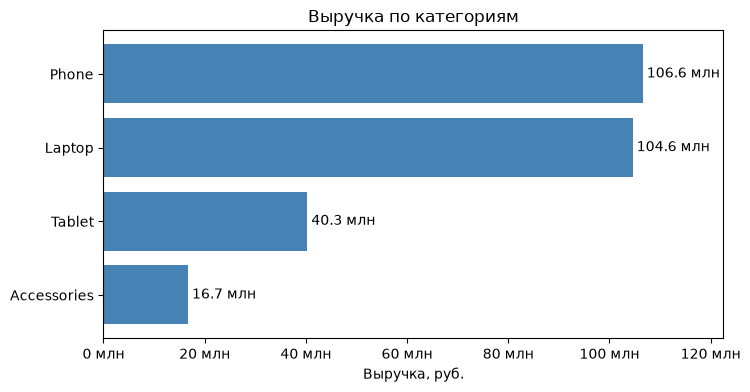

In [3]:
def plot_revenue_by_category(df: pd.DataFrame) -> plt.Figure:
    """Строит горизонтальную диаграмму выручки по категориям."""
    revenue = df.groupby("category")["total"].sum().sort_values()
    fig, ax = plt.subplots(figsize=(8, 4))
    bars = ax.barh(revenue.index, revenue.values, color="steelblue")
    ax.bar_label(bars, labels=[f"{v / 1e6:.1f} млн" for v in revenue.values],
                 padding=3)
    ax.xaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v / 1e6:.0f} млн"))
    ax.set_xlabel("Выручка, руб.")
    ax.set_title("Выручка по категориям")
    ax.set_xlim(right=revenue.max() * 1.15)  # место для подписей
    return fig

fig = plot_revenue_by_category(sold)
plt.show()

### Пример 3. Динамика выручки с отметкой максимума

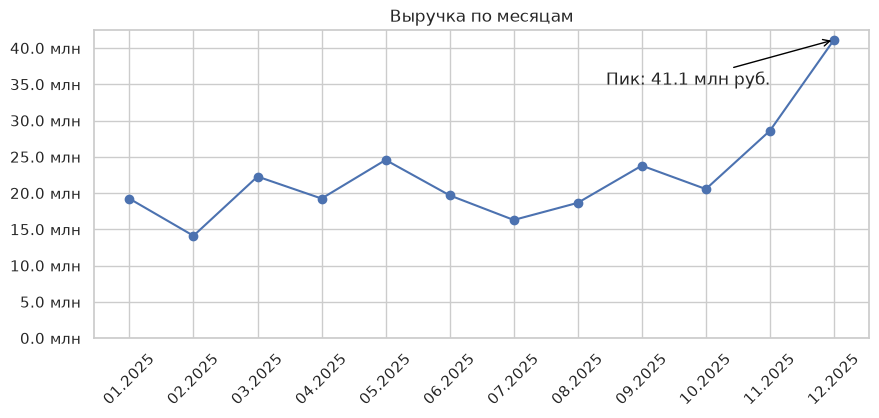

In [4]:
sns.set_theme(style="whitegrid")

def to_millions(value: float, _pos: int) -> str:
    return f"{value / 1_000_000:.1f} млн"

monthly = sold.groupby("month")["total"].sum()
labels = monthly.index.strftime("%m.%Y")

fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(labels, monthly.values, marker="o")
peak = monthly.values.argmax()
ax.annotate(f"Пик: {to_millions(monthly.max(), 0)} руб.",
            xy=(peak, monthly.max()),
            xytext=(peak - 1, monthly.max() * 0.85), ha="right",
            arrowprops={"arrowstyle": "->", "color": "black"})
ax.set_ylim(bottom=0)
ax.yaxis.set_major_formatter(FuncFormatter(to_millions))
ax.tick_params(axis="x", labelrotation=45)
ax.set_title("Выручка по месяцам")
plt.show()

### Пример 4. Сводная таблица и тепловая карта

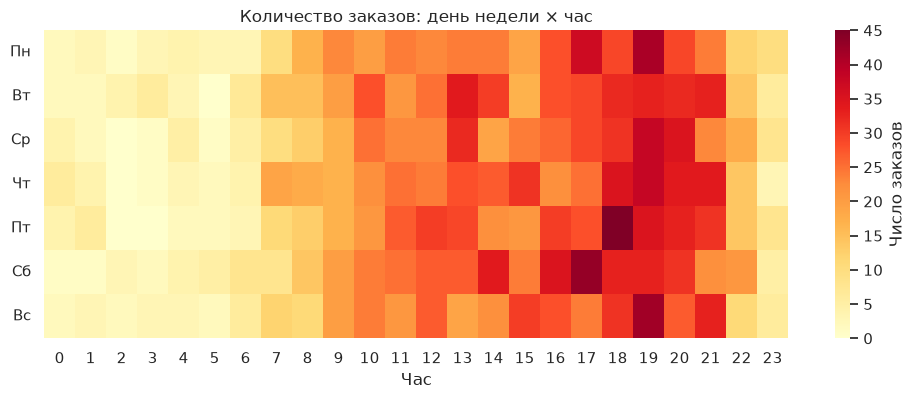

In [5]:
df["weekday"] = df["order_datetime"].dt.day_of_week  # 0 — понедельник
df["hour"] = df["order_datetime"].dt.hour

activity = df.pivot_table(index="weekday", columns="hour", values="order_id",
                          aggfunc="count", fill_value=0)

fig, ax = plt.subplots(figsize=(12, 4))
sns.heatmap(activity, cmap="YlOrRd", ax=ax,
            cbar_kws={"label": "Число заказов"})
ax.set_yticklabels(["Пн", "Вт", "Ср", "Чт", "Пт", "Сб", "Вс"], rotation=0)
ax.set_xlabel("Час")
ax.set_ylabel("")
ax.set_title("Количество заказов: день недели × час")
plt.show()

### Пример 5. Seaborn: сравнение распределений

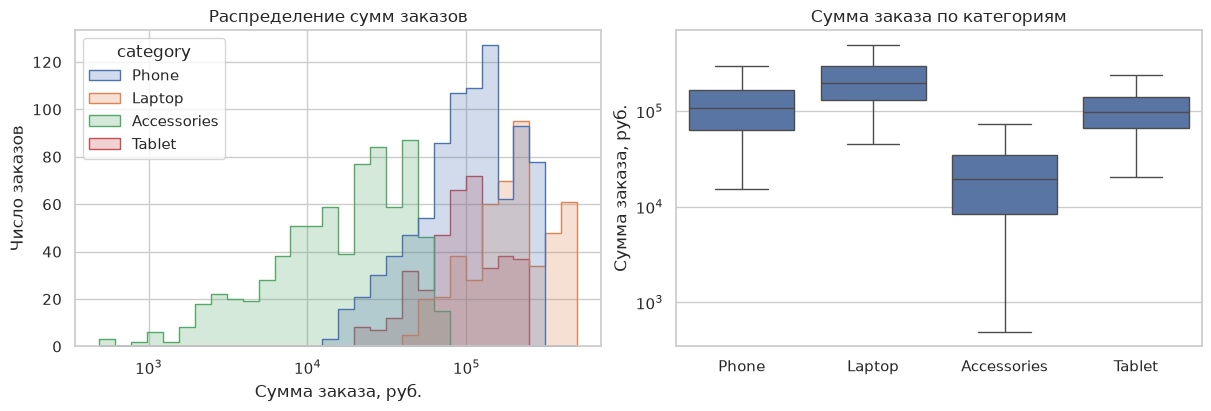

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4), layout="constrained")

sns.histplot(data=sold, x="total", hue="category", element="step",
             log_scale=True, ax=axes[0])
axes[0].set_xlabel("Сумма заказа, руб.")
axes[0].set_ylabel("Число заказов")
axes[0].set_title("Распределение сумм заказов")

sns.boxplot(data=sold, x="category", y="total", ax=axes[1])
axes[1].set_yscale("log")  # суммы различаются на порядки
axes[1].set_xlabel("")
axes[1].set_ylabel("Сумма заказа, руб.")
axes[1].set_title("Сумма заказа по категориям")
plt.show()

### Пример 6. Интерактивный график Plotly

In [7]:
by_month = (
    sold.groupby([pd.Grouper(key="order_datetime", freq="ME"), "category"])
    ["total"].sum()
    .reset_index()
)

fig = px.bar(by_month, x="order_datetime", y="total", color="category",
             title="Выручка по месяцам и категориям",
             labels={"order_datetime": "Месяц", "total": "Выручка, руб.",
                     "category": "Категория"})
fig.write_html("lab5_output/revenue_by_category.html")
fig.show()

---
## Часть II. Задания

### Задания на освоение концепции (1–10)

**Задание 1. Интерфейсы pyplot и объектный.**
Постройте линейный график выручки за 12 месяцев (данные заданы в заготовке ноутбука) двумя способами: через `plt.plot()` и через `fig, ax = plt.subplots()`. Добавьте второй ряд — выручку прошлого года — и легенду. Объясните в комментарии, почему внутри функций следует использовать объектный интерфейс.

In [ ]:
import matplotlib.pyplot as plt
months = ["Янв","Фев","Мар","Апр","Май","Июн","Июл","Авг","Сен","Окт","Ноя","Дек"]
revenue_2025 = [23.3,17.2,26.1,22.3,28.8,23.5,20.6,22.9,28.8,25.9,36.2,48.9]
revenue_2024 = [19.8,16.5,21.0,20.4,23.9,21.7,18.2,20.1,24.6,23.0,31.5,41.2]
plt.plot(months, revenue_2025, label="2025"); plt.plot(months, revenue_2024, label="2024"); plt.legend(); plt.show()
fig, ax = plt.subplots(); ax.plot(months, revenue_2025, label="2025"); ax.plot(months, revenue_2024, label="2024"); ax.legend(); plt.show()
# El interfaz de objetos evita depender del estado global dentro de funciones.


**Задание 2. Оформление графика.**
Доработайте график из задания 1:

1. Добавьте заголовок, подписи осей с единицами измерения и сетку (`alpha=0.3`).
2. Переведите значения в рубли и отформатируйте ось Y через `FuncFormatter` так, чтобы деления выглядели как «25,0 млн» — с запятой в качестве десятичного разделителя.
3. Поверните подписи оси X на 45° и выделите месяц с максимальной выручкой отдельной точкой другого цвета (`ax.scatter`).

In [ ]:
from matplotlib.ticker import FuncFormatter
def format_millions(value: float, _pos: int) -> str:
    return f"{value / 1_000_000:.1f}".replace(".", ",") + " млн"
fig, ax = plt.subplots(); values = [x * 1_000_000 for x in revenue_2025]
ax.plot(months, values); ax.yaxis.set_major_formatter(FuncFormatter(format_millions))
ax.set(title="Выручка", xlabel="Месяц", ylabel="Рубли"); ax.grid(alpha=0.3); ax.tick_params(axis="x", rotation=45)
i = values.index(max(values)); ax.scatter([months[i]], [values[i]], color="red"); plt.show()


**Задание 3. Столбчатые диаграммы.**
Дано количество проданных товаров по брендам (см. заготовку в ноутбуке).

1. Постройте вертикальную (`bar`) и горизонтальную (`barh`) диаграммы на одной фигуре.
2. Отсортируйте бренды по убыванию продаж. Объясните, почему отсортированную диаграмму читать проще.
3. Подпишите значения у столбцов через `ax.bar_label`.
4. Постройте ту же диаграмму с `ax.set_ylim(150, 420)` и объясните, как обрезанная ось искажает восприятие разницы между брендами.

In [ ]:
brand_sales = {"Apple": 412, "Samsung": 388, "Lenovo": 205, "Asus": 176, "Xiaomi": 301}
ordered = sorted(brand_sales.items(), key=lambda item: item[1], reverse=True)
labels, values = zip(*ordered); fig, axes = plt.subplots(1, 3, figsize=(14, 4), layout="constrained")
bars = axes[0].bar(labels, values); axes[0].bar_label(bars)
bars = axes[1].barh(labels[::-1], values[::-1]); axes[1].bar_label(bars)
bars = axes[2].bar(labels, values); axes[2].set_ylim(150, 420); axes[2].bar_label(bars)
plt.show()
# Ordenar facilita comparar rangos; recortar el eje exagera las diferencias.


**Задание 4. Гистограмма и число интервалов.**
1. Сгенерируйте 1000 сумм заказов через `random.lognormvariate(9, 1)` — у такого распределения длинный правый «хвост», как у реальных чеков.
2. Постройте на одной фигуре (1 × 3) гистограммы с `bins=5`, `bins=30` и `bins="auto"`. Какой вариант лучше передаёт форму распределения?
3. Постройте гистограмму с логарифмической шкалой по оси X (`ax.set_xscale("log")`), интервалы задайте через `np.logspace`. Что изменилось?
4. Отметьте среднее и медиану вертикальными линиями (`ax.axvline`) и подпишите их в легенде. Почему они не совпадают?

In [ ]:
import random
import numpy as np
random.seed(5)
totals = [random.lognormvariate(9, 1) for _ in range(1000)]
fig, axes = plt.subplots(1, 3, figsize=(13, 4), layout="constrained")
for ax, bins in zip(axes, [5, 30, "auto"]): ax.hist(totals, bins=bins); ax.set_title(f"bins={bins}")
plt.show()
fig, ax = plt.subplots(); ax.hist(totals, bins=np.logspace(np.log10(min(totals)), np.log10(max(totals)), 30)); ax.set_xscale("log")
ax.axvline(np.mean(totals), color="red", label="Среднее"); ax.axvline(np.median(totals), color="blue", label="Медиана"); ax.legend(); plt.show()


**Задание 5. Диаграмма рассеяния.**
Для 200 заказов даны цена товара и количество (см. заготовку в ноутбуке). Постройте `scatter`, где цвет точки соответствует сумме заказа (`c=`, `cmap="viridis"`), добавьте цветовую шкалу `fig.colorbar()` и прозрачность `alpha=0.6`. Есть ли зависимость между ценой и количеством? Как это видно на графике?

In [ ]:
random.seed(7)
prices = [random.randint(5_000, 250_000) for _ in range(200)]
quantities = [random.randint(1, 5) for _ in range(200)]
totals_scatter = np.array(prices) * np.array(quantities)
fig, ax = plt.subplots(); points = ax.scatter(prices, quantities, c=totals_scatter, cmap="viridis", alpha=0.6)
fig.colorbar(points, ax=ax, label="Сумма заказа"); ax.set(xlabel="Цена", ylabel="Количество"); plt.show()


**Задание 6. Несколько графиков на одной фигуре.**
Создайте фигуру 2 × 2 (`plt.subplots(2, 2, layout="constrained")`) и разместите на ней графики из заданий 1, 3, 4 и 5. Каждый график рисуйте отдельной функцией вида `draw_xxx(ax: plt.Axes, ...) -> None`, которая получает готовые оси и ничего не создаёт сама. Добавьте общий заголовок `fig.suptitle()`.

In [ ]:
def draw_revenue(ax: plt.Axes, months: list[str], values: list[float]) -> None:
    ax.plot(months, values, marker="o"); ax.set(title="Выручка", xlabel="Месяц", ylabel="Млн руб.")
def draw_brands(ax, labels, values):
    bars = ax.bar(labels, values); ax.bar_label(bars)
def draw_distribution(ax, values): ax.hist(values, bins="auto")
def draw_scatter(ax, x, y): ax.scatter(x, y, c=np.array(x)*np.array(y), cmap="viridis", alpha=0.6)
fig, axes = plt.subplots(2, 2, layout="constrained"); draw_revenue(axes[0,0], months, revenue_2025); draw_brands(axes[0,1], labels, values); draw_distribution(axes[1,0], totals); draw_scatter(axes[1,1], prices, quantities); fig.suptitle("Обзор"); plt.show()


**Задание 7. Seaborn: сравнение групп.**
В заготовке ноутбука создаётся DataFrame с суммами заказов по трём каналам продаж.

1. Постройте `sns.histplot` с `hue="channel"` и `element="step"`.
2. Постройте `sns.boxplot` и `sns.violinplot` по каналам на одной фигуре. Какая информация видна на violinplot, но не видна на boxplot?
3. Постройте `sns.barplot` по каналам дважды: со значениями по умолчанию и с `estimator="sum"`. Объясните, что показывает каждый вариант и что означают чёрные отрезки над столбцами.

In [ ]:
import random
random.seed(11)
mu = {"web": 9.3, "mobile": 9.1, "marketplace": 8.6}
sales = pd.DataFrame([{"channel": ch, "total": round(random.lognormvariate(value, 0.9))} for ch, value in mu.items() for _ in range(200)])
fig, axes = plt.subplots(1, 3, figsize=(14, 4), layout="constrained")
sns.histplot(data=sales, x="total", hue="channel", element="step", ax=axes[0])
sns.boxplot(data=sales, x="channel", y="total", ax=axes[1]); sns.violinplot(data=sales, x="channel", y="total", ax=axes[2]); plt.show()


**Задание 8. Тепловая карта.**
1. Создайте DataFrame продаж со столбцами `month` (1–12), `category` и `total` (не менее 500 строк, случайные значения).
2. Через `pivot_table` постройте таблицу «категория × месяц» с суммой выручки в тысячах рублей.
3. Визуализируйте её через `sns.heatmap` с подписями значений (`annot=True`, `fmt=".0f"`).
4. Сравните палитры `"Blues"` и `"coolwarm"`. Почему для неотрицательных величин лучше подходит последовательная палитра, а не расходящаяся?

In [ ]:
import random
random.seed(21)
heat = pd.DataFrame({"month":[random.randint(1,12) for _ in range(600)], "category":[random.choice(["Laptop","Phone","Tablet","Accessories"]) for _ in range(600)], "total":[random.randint(500,250000) for _ in range(600)]})
pivot = heat.pivot_table(index="category", columns="month", values="total", aggfunc="sum", fill_value=0) / 1000
sns.heatmap(pivot, annot=True, fmt=".0f", cmap="Blues"); plt.show()


**Задание 9. Plotly: интерактивный график.**
Повторите диаграмму из задания 3 с помощью `plotly.express.bar`. Добавьте в подсказку (`hover_data`) долю бренда в процентах. Сохраните график в `brands.html` через `write_html`, скачайте файл и откройте его в браузере. Перечислите, какие возможности появились по сравнению с Matplotlib.

In [ ]:
brand_frame = pd.DataFrame({"brand": list(brand_sales), "sales": list(brand_sales.values())})
brand_frame["share"] = brand_frame["sales"] / brand_frame["sales"].sum() * 100
fig = px.bar(brand_frame, x="brand", y="sales", hover_data={"share":":.1f"}); fig.write_html("brands.html"); fig.show()


**Задание 10. Форматы файлов и память.**
1. Сохраните один и тот же график в PNG (`dpi=72` и `dpi=300`), SVG и PDF. Выведите размеры файлов через `os.path.getsize`. Увеличьте изображение каждого формата — какой из них остаётся чётким?
2. В цикле постройте 30 фигур без `plt.close()`. Посмотрите на предупреждение и выведите `len(plt.get_fignums())`. Исправьте код.
3. Объясните, какой формат выбрать для отчёта в PDF, для веб-страницы и для презентации.

In [ ]:
from pathlib import Path
out = Path("lab5_output"); out.mkdir(exist_ok=True); fig, ax = plt.subplots(); ax.bar(labels, values)
for dpi in (72, 300): fig.savefig(out / f"brands_{dpi}.png", dpi=dpi)
fig.savefig(out / "brands.svg"); fig.savefig(out / "brands.pdf"); plt.close(fig)
for _ in range(30): f, a = plt.subplots(); plt.close(f)
print("Figuras abiertas:", len(plt.get_fignums()))


---
### Задания по прикладной задаче (11–20)

**Прикладная задача:** «Визуальная аналитика продаж интернет-магазина».

Магазин из ЛР2 накопил данные о заказах за 2025 год (файл `lab5_data/orders.csv` создан в ячейке инициализации). Руководству нужен не текстовый отчёт, а набор графиков: как менялась выручка, что и где покупают, когда клиенты наиболее активны. Формат файла:

```
order_id,order_datetime,customer_id,city,category,brand,unit_price,quantity,channel,status
ORD-10000,2025-01-01 11:27,cust_163,Москва,Phone,Asus,149590,2,web,completed
ORD-10001,2025-01-01 13:19,cust_196,Москва,Laptop,Apple,168090,2,web,shipped
```

где новые по сравнению с ЛР2 поля:

*   `order_datetime` — дата и время оформления заказа;
*   `city` — город доставки;
*   `category`, `brand` — категория и бренд товара;
*   `channel` — канал продаж (`web`, `mobile`, `marketplace`).

**Внимание:** в файле есть несколько некорректных строк (пустая цена, отрицательное количество). Их нужно обнаружить и исключить при загрузке, а не «молча» проглотить.

**Постановка задачи.** Требуется построить модуль, который:

*   загружает и проверяет данные;
*   считает агрегаты средствами pandas;
*   строит статические (Matplotlib, Seaborn) и интерактивные (Plotly) графики;
*   сохраняет графики в `lab5_output/` и собирает их в единый HTML-отчёт;
*   использует функции из ЛР2, обработку исключений и логирование из ЛР3, принципы SOLID из ЛР4.

**Задание 11. Настройка окружения и загрузка данных**
Инициализируйте папку `lab5` в репозитории `python-labs`. Напишите функцию `load_orders(path: str) -> pd.DataFrame`, которая:

1. Читает CSV через `pd.read_csv` с `parse_dates=["order_datetime"]`.
2. Проверяет наличие всех обязательных столбцов. Если хотя бы одного нет — поднимает собственное исключение `DataValidationError` с перечнем недостающих столбцов.
3. Приводит `unit_price` и `quantity` к числам через `pd.to_numeric(..., errors="coerce")`, удаляет строки с пропусками и неположительными значениями. Количество удалённых строк записывает в лог (`logging.warning`).
4. Добавляет вычисляемые столбцы `total`, `month` (через `dt.to_period("M")`), `weekday` и `hour`.

Проверьте: сколько строк было в файле и сколько осталось после очистки?

In [ ]:
from pathlib import Path
Path("lab5_data").mkdir(exist_ok=True); Path("lab5_output").mkdir(exist_ok=True)


In [ ]:
from sales_report import DataValidationError, load_orders
orders = load_orders("lab5_data/orders.csv"); print("Filas limpias:", len(orders))


**Задание 12. Функции агрегации**
Напишите набор функций. Они ничего не рисуют и не печатают — только считают (SRP):

1. `sold_orders(df) -> pd.DataFrame` — только заказы со статусами `completed` и `shipped` (отменённые и неоплаченные в выручку не входят).
2. `revenue_by_month(df) -> pd.Series` — выручка по месяцам.
3. `revenue_by(df, column: str) -> pd.Series` — выручка в разрезе произвольного столбца (`category`, `city`, `channel`, `brand`) по убыванию. Для несуществующего столбца — `ValueError`.
4. `kpi(df) -> dict` — выручка, количество оплаченных заказов, средний чек и доля отменённых заказов в процентах.

In [ ]:
from sales_report import sold_orders, revenue_by_month, revenue_by, kpi
print(kpi(orders))


**Задание 13. Динамика выручки**
Напишите функцию `plot_monthly_revenue(df: pd.DataFrame) -> plt.Figure`:

1. Линейный график выручки по месяцам с маркерами.
2. Ось Y начинается с нуля, значения подписаны в миллионах рублей.
3. Месяц с максимальной выручкой подписан через `ax.annotate`.
4. Пунктирной горизонтальной линией (`ax.axhline`) отмечена средняя месячная выручка.

По графику ответьте: есть ли в данных сезонность? В какие месяцы?

In [ ]:
from sales_report import plot_monthly_revenue
fig = plot_monthly_revenue(orders); plt.show()


**Задание 14. Структура продаж**
Напишите функцию `plot_category_structure(df) -> plt.Figure`, которая строит на одной фигуре два графика:

1. Слева — составную столбчатую диаграмму выручки по месяцам с разбивкой по категориям (`pivot_table` + `DataFrame.plot(kind="bar", stacked=True, ax=...)`).
2. Справа — ту же диаграмму в процентах: каждый месяц нормирован на 100 %.

Объясните, какие выводы видны на левом графике, а какие — только на правом. Почему здесь не подходит набор из 12 круговых диаграмм?

In [ ]:
from sales_report import plot_category_structure
fig = plot_category_structure(orders); plt.show()


**Задание 15. Средний чек и распределение сумм**
Напишите функцию `plot_order_distribution(df) -> plt.Figure`:

1. Гистограмма сумм заказов (логарифмическая шкала по X) с вертикальными линиями среднего и медианы.
2. `sns.boxplot` сумм заказов по каналам продаж.

Ответьте: в каком канале средний чек выше? Какие заказы видны как выбросы и стоит ли удалять их из анализа?

In [ ]:
from sales_report import plot_order_distribution
fig = plot_order_distribution(orders); plt.show()


**Задание 16. Тепловая карта активности**
Напишите функцию `plot_activity_heatmap(df) -> plt.Figure`, которая строит тепловую карту «день недели × час» по количеству заказов. Дни недели подпишите по-русски (Пн … Вс). По графику определите: в какое время лучше запускать рассылку со скидками, а в какие часы проводить технические работы на сайте?

In [ ]:
from sales_report import plot_activity_heatmap
fig = plot_activity_heatmap(orders); plt.show()


**Задание 17. Карта продаж**
Напишите функцию `plot_sales_map(df, cities: dict[str, tuple[float, float]]) -> go.Figure`, которая:

1. Считает выручку и количество заказов по городам.
2. Добавляет координаты из словаря `CITIES` (ячейка инициализации). Если для города нет координат — пропускает его с предупреждением в логе.
3. Строит `px.scatter_geo`: размер маркера — выручка, в подсказке — город, выручка и число заказов. Чтобы карта показывала только нужную территорию, используйте `fig.update_geos(fitbounds="locations")`.
4. Сохраняет карту в `lab5_output/sales_map.html`.

In [ ]:
from sales_report import CITIES, plot_sales_map
fig = plot_sales_map(orders, CITIES); fig.show()


**Задание 18. Построители графиков (OCP)**
Чтобы добавлять новые графики, не меняя код отчёта, вынесите каждый график в отдельный класс:

1. Создайте абстрактный класс `ChartBuilder(ABC)` с атрибутами `title: str`, `filename: str` и абстрактными методами `build(df) -> object` и `save(fig, path: Path) -> Path`.
2. Реализуйте наследника `MatplotlibChart`, который сохраняет фигуру в PNG и закрывает её, и наследника `PlotlyChart`, который сохраняет в HTML.
3. На их основе реализуйте `MonthlyRevenueChart`, `CategoryStructureChart`, `OrderDistributionChart`, `ActivityHeatmapChart` и `SalesMapChart`, используя функции из заданий 13–17.
4. Покажите, что для добавления нового графика (например, выручки по брендам) достаточно создать новый класс и добавить его в список построителей.

In [ ]:
from sales_report import (ChartBuilder, MatplotlibChart, PlotlyChart, MonthlyRevenueChart, CategoryStructureChart, OrderDistributionChart, ActivityHeatmapChart, SalesMapChart)


**Задание 19. Сохранение графиков с изоляцией ошибок**
Напишите функцию `render_charts(builders: list[ChartBuilder], df: pd.DataFrame, output_dir: Path) -> dict[str, list]`, которая:

1. Создаёт каталог `output_dir/figures/`.
2. Для каждого построителя строит и сохраняет график.
3. Если один график завершился ошибкой, логирует её через `logger.exception` и продолжает работу с остальными — как конвейер в ЛР3.
4. Возвращает словарь `{"saved": [...пути...], "failed": [...названия...]}`.

Проверьте изоляцию: добавьте в список построитель, который намеренно поднимает исключение.

In [ ]:
from sales_report import render_charts
builders = [MonthlyRevenueChart(), CategoryStructureChart(), OrderDistributionChart(), ActivityHeatmapChart(), SalesMapChart()]
print(render_charts(builders, orders, Path("lab5_output")))


**Задание 20. Комплексный отчёт и сдача**
Перенесите функции и классы из заданий 11–19 в модуль `sales_report.py`:

1. Функция `build_html_report(kpi: dict, charts: list[tuple[str, Path]], output_path: Path) -> Path` формирует `lab5_output/report.html`:
    *   заголовок и блок ключевых показателей (задание 12);
    *   PNG-графики через тег `<img>` и ссылку на интерактивную карту;
    *   относительные пути к файлам, чтобы папку `lab5_output/` можно было переносить целиком.
2. Функция `main() -> int` — оркестратор:
    *   загружает данные, считает KPI, строит графики, формирует отчёт;
    *   возвращает код выхода: 0 — всё построено, 1 — часть графиков не построена, 2 — данные не прошли проверку.
3. Точка входа: `if __name__ == "__main__": sys.exit(main())`.
4. Для запуска вне ноутбука включите бэкенд без окна: `matplotlib.use("Agg")` до импорта `pyplot`.
5. Все функции и классы — с аннотациями типов и docstring. Проверьте код через `flake8`.
6. Создайте `README.md`: опишите структуру модуля и обоснуйте выбор типа для каждого графика. Сделайте коммит и `git push` в GitLab.

**Критерии оценки:**

*   У каждого графика есть заголовок, подписи осей и единицы измерения.
*   Тип графика соответствует задаче, выбор обоснован.
*   Расчёты отделены от построения графиков, построение — от сохранения (SRP).
*   Новый график добавляется без изменения кода отчёта (OCP).
*   Ошибка одного графика не останавливает построение отчёта.
*   Соблюдён PEP 8.
*   Код в GitLab, ноутбук выполняется без ошибок.

In [ ]:
from sales_report import main
print("Código de salida:", main())


In [ ]:
import subprocess
print("Código de salida:", subprocess.run(["python", "sales_report.py"], check=False).returncode)


In [ ]:
from pathlib import Path
Path("README.md").write_text("# Laboratorio 5\n\nVisualización de ventas con Matplotlib, Seaborn y Plotly.\n", encoding="utf-8")


In [ ]:
print("Commit y push se realizan manualmente para preservar el historial del repositorio.")


## Контрольные вопросы

1. Чем Figure отличается от Axes? Сколько Axes может быть на одной Figure?
2. В чём разница между pyplot-интерфейсом и объектным интерфейсом Matplotlib? Какой из них использовать внутри функций и почему?
3. Какой тип графика выбрать для показа динамики, сравнения категорий, распределения и связи двух величин?
4. Почему ось Y столбчатой диаграммы должна начинаться с нуля, а для линейного графика это не обязательно?
5. Как число интервалов влияет на вид гистограммы? Когда полезна логарифмическая шкала?
6. Что показывает «ящик с усами»? Как в нём определяются выбросы?
7. Что такое «длинный» (tidy) формат данных и почему Seaborn ожидает именно его?
8. Что по умолчанию показывает `sns.barplot` и как получить сумму вместо среднего?
9. Чем растровые форматы отличаются от векторных? Когда выбирать PNG, а когда SVG или PDF?
10. Почему фигуры Matplotlib нужно закрывать при построении в цикле?
11. В чём преимущества и недостатки интерактивных графиков Plotly по сравнению со статическими?

## Ответы

1. Figure — это общий холст, а Axes — отдельная область построения. На одной Figure может быть несколько Axes.
2. pyplot использует текущие глобальные оси, а объектный интерфейс работает с явно переданными Axes. В функциях лучше использовать объектный интерфейс, потому что он изолирует состояние графика.
3. Для динамики используют линейный график, для категорий — столбчатый, для распределения — гистограмму или boxplot, для связи двух величин — scatter.
4. Начало с нуля не искажает относительную длину столбцов. Для линейного графика масштаб можно выбирать для лучшего отображения изменений.
5. Малое число интервалов скрывает детали, а слишком большое делает график шумным. Логарифмическая шкала полезна при длинном хвосте и больших различиях значений.
6. Boxplot показывает медиану, квартили и разброс данных. Выбросами считают значения за пределами 1,5 межквартильных размаха.
7. Tidy-формат означает: одна строка — одно наблюдение, один столбец — одна переменная. Такой формат удобен для анализа групп средствами Seaborn.
8. `sns.barplot` по умолчанию показывает среднее. Для суммы используют `estimator="sum"`.
9. Растровые форматы состоят из пикселей, а векторные сохраняют линии и текст без потери качества. PNG подходит для веба, SVG и PDF — для отчётов и печати.
10. Закрытие освобождает память и предотвращает накопление большого числа открытых Figure при построении в цикле.
11. Plotly поддерживает масштабирование, подсказки и фильтрацию, но интерактивные файлы обычно тяжелее статических графиков и требуют браузера.


## Дополнительно

1. Оформите выполненные задания в виде Jupyter-ноутбука `lab5_visualization.ipynb`.
2. Убедитесь, что ноутбук выполняется сверху вниз без ошибок (Kernel → Restart & Run All).
3. В репозитории `python-labs` создайте папку `lab5` и добавьте туда ноутбук, модуль `sales_report.py` и `README.md`.
4. Добавьте в `.gitignore` каталоги `lab5_data/` и `lab5_output/` (данные и графики генерируются кодом), а также `__pycache__/` и `.ipynb_checkpoints/`. Два-три итоговых графика положите в `lab5/img/` и вставьте в `README.md`.
5. Зафиксируйте изменения:
```bash
git add .
git commit -m "ЛР5: визуализация данных, отчёт по продажам магазина"
git push origin main
```
6. В конце `README.md` добавьте раздел «Ссылка на репозиторий» и укажите URL.
7. Прикрепите ссылку и ноутбук в системе дистанционного обучения.